# Lecture 13 notebook: when the market trades

This notebook replays Lecture 13 on the tape built in Lecture 12: it builds bars on six clocks, compares them, builds imbalance bars in
López de Prado's construction and in our fixed-band version, and tests the market's calendar as five hypotheses. Every figure and every
number of the lecture comes from a script in `scripts/`, next to this notebook; the notebook runs each script in a fresh process, so
that memory is freed after every step, and then shows its figures and tables.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings: data folder, memory, what to expect | |
| 1 | Building bars: six clocks, thresholds from the past, constants from the burn-in | §2, §3.1 |
| 2 | The clocks compared: where they tick, the crash of 10 October 2025, extreme days, robustness, normality | §3–§5 |
| 3 | Imbalance bars: López de Prado's construction, its failures, the fixed band | §6 |
| 4 | Seasonality: five hypotheses, the daylight-saving test, round times, releases, expiries, when each clock trades | §7 |
| 5 | A calendar test of your own | §7.1, exercises |

**Before you start.** Lecture 12's notebook must have built the tape for the whole period, October 2021 to September 2026 (§1 there):
this notebook reads its derived tables and its trades. Data stay in `data/` at the top of the repository, or in the folder of the
environment variable `TAPE_ROOT`; results of this notebook go to `data/interim/l13`. Nothing is committed. Figures are saved in
`figures/` under names starting with `nb_`, so the lecture's own figures are never overwritten.

## 0. Settings

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import polars as pl, psutil
from IPython.display import Image, Markdown, display

HERE = Path.cwd()                                   # the folder of this notebook
SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS), str(HERE.parent / "12-tick-data-the-tape"), str(HERE.parents[1])]
import tape
OUT = tape.ROOT / "interim" / "l13"

SYMBOL = "BTCUSDT"       # the lecture's market; the scripts' fixed dates (the Fed day, 10 October 2025) are those of the lecture
RUN_IMBALANCE = False    # §3 takes about 6 minutes; False shows the results of an earlier run, if there is one

pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200)
print("data folder:", "the folder in the environment variable TAPE_ROOT" if os.environ.get("TAPE_ROOT") else "data/ at the top of the repository")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, show=False):
    """Run a script of scripts/ in a fresh process; its figures go to figures/ as nb_*, its results to data/interim/l13."""
    t0 = time.time()
    env = {**os.environ, "TAPE_ROOT": str(tape.ROOT), "L13_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def result(name):
    return json.loads((OUT / name).read_text(encoding="utf-8"))


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def table(rows, **kw):
    return pl.DataFrame(rows, **kw)

data folder: the folder in the environment variable TAPE_ROOT
free memory: 4.2 GB of 16.9 GB


**What to expect.** Measured on a computer with 16 GB of memory, of which often less than 3 GB were free:

| Step | Time | Peak memory |
|---|---|---|
| §1 Bars on six clocks, five years, first run | about 30 minutes, one month per process | 3 to 4 GB (the busiest month) |
| §1 Later runs | seconds: months already built are skipped | |
| §2 The clocks compared | about a minute | about 2 GB |
| §3 Imbalance bars | about 6 minutes | about 4.5 GB |
| §4 Seasonality | under a minute | about 2 GB |

*The first time a step reads five years of trades from disk it takes longer; these times were measured with the data already read once.*

Every step waits when free memory runs low, rather than letting the computer run out.

## 1. Building bars

Six clocks (lecture §2): time (30 minutes), tick, volume, dollar, range and CUSUM, each at about 48 bars a day. Each day's threshold comes
from the median of the 28 days before (§3.4); the price clocks follow one price per second, the volume-weighted average of that second
(§3.5). The constants that scale the price clocks are set once, on the first three months of data, October to December 2021, and never
changed (§3.1). Each month is built in its own process, and the unfinished bar of a month is carried into the next through a file.

The cell below builds the bars that are missing; months already built are skipped. To rebuild everything, add `"--rebuild"`.

In [2]:
run("bars.py", "all", SYMBOL)
import bars
per_day = []
for k in bars.TYPES:
    b = pl.scan_parquet(sorted(bars.bars_dir(SYMBOL, k).glob("*.parquet"))).select("end_ms").collect()
    per_day.append((k, b.height, round(b.height / b.select((pl.col("end_ms") // 86_400_000).n_unique()).item(), 1)))
table(per_day, schema=["clock", "bars", "bars per day"], orient="row")

bars.py: 1 s


clock,bars,bars per day
str,i64,f64
"""time""",87312,48.0
"""tick""",96762,53.2
"""volume""",93594,51.5
"""dollar""",93873,51.6
"""range""",104205,57.3
"""cusum""",104092,57.2


**The burn-in constants.** The cell below recomputes the multiples of the price clocks on October to December 2021 (lecture §3.1: 1.43 for
range, 1.44 for CUSUM). It builds three months of bars in a separate folder and takes a few minutes; the bars in use are not touched.

In [3]:
CALIBRATE = False        # True: recompute the constants of the price clocks on the burn-in
if CALIBRATE:
    run("bars.py", "calibrate", SYMBOL, show=True)
print("in use:", {"range": bars.K_RANGE, "cusum": bars.K_CUSUM})

in use: {'range': 1.431, 'cusum': 1.442}


## 2. The clocks compared

Lecture §3 to §5: where each clock ticks, how fast it runs, a fixed against an adaptive threshold, the crash of 10 October 2025, the most
extreme days, the robustness of the price clocks to their settings, and how normal each clock's returns are.

### 2.1 Where each clock ticks (§3.2 to §3.4)

l13_s3_charts.py: 7 s


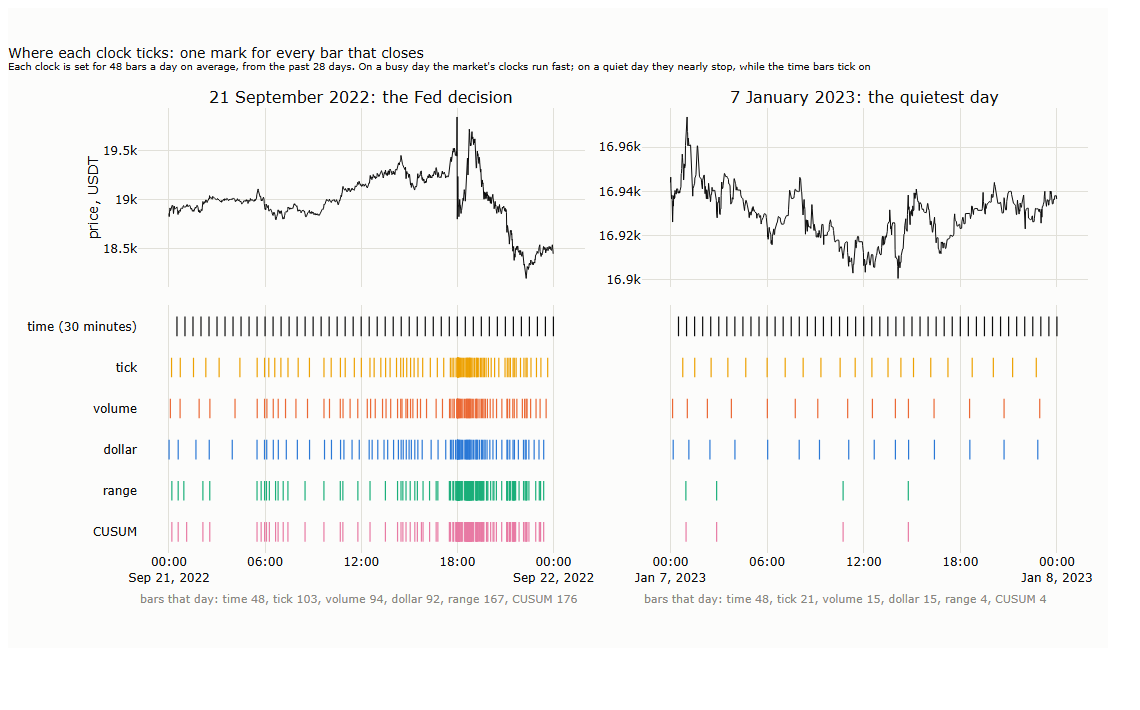

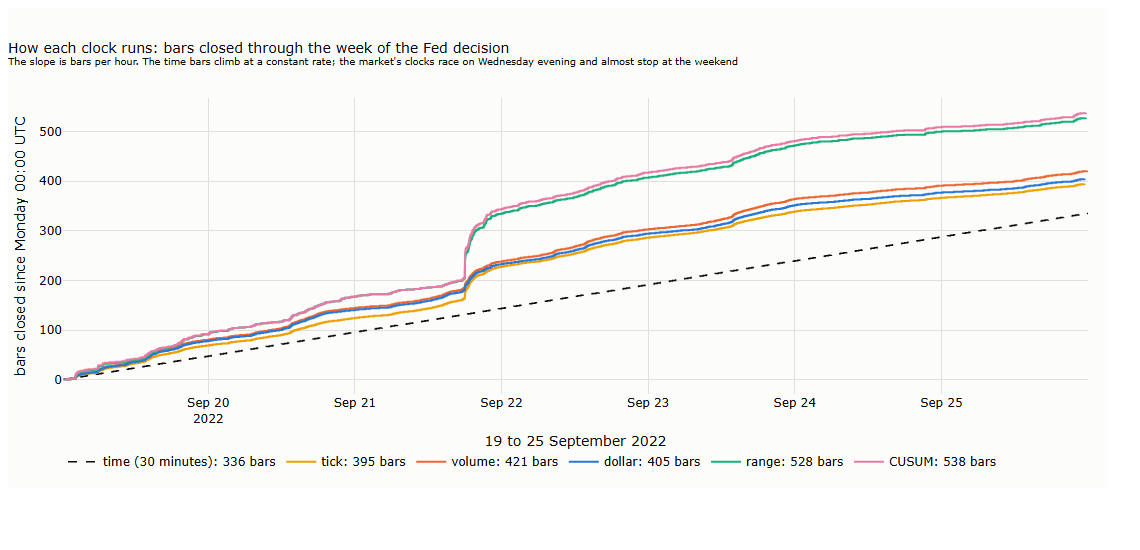

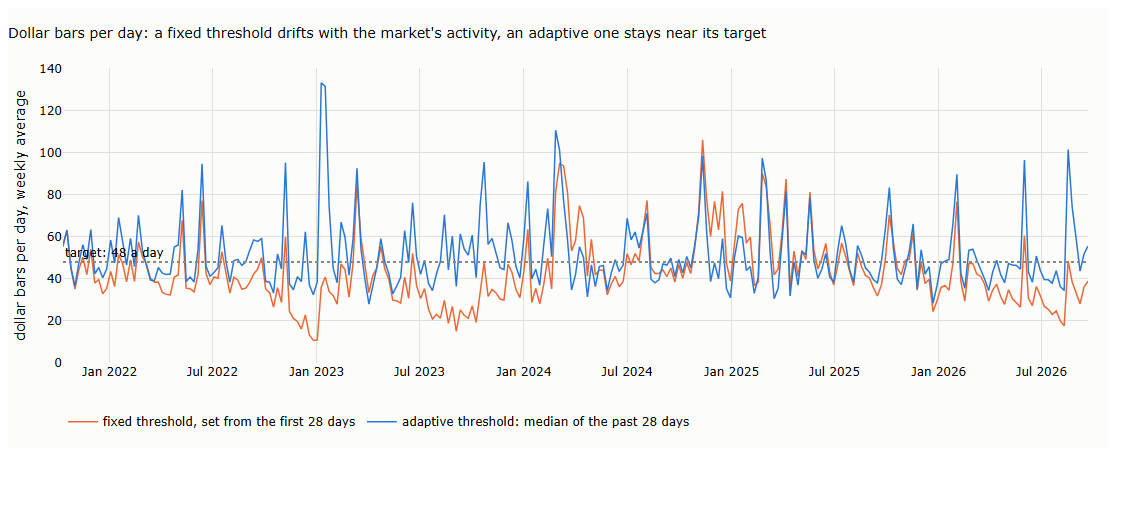

day,time,tick,volume,dollar,range,cusum
str,i64,i64,i64,i64,i64,i64
"""2022-09-21""",48,103,94,92,167,176
"""2023-01-07""",48,21,15,15,4,4


In [4]:
run("l13_s3_charts.py")
pictures("13_01_where_clocks_tick", "13_02_how_clocks_run", "13_03_fixed_vs_adaptive")
s3 = result("l13_s3.json")
table([{"day": k.replace("bars_on_", ""), **v} for k, v in s3.items() if k.startswith("bars_on_")])

### 2.2 The crash of 10 October 2025 and the most extreme days (§3.5)

l13_oct10.py: 5 s


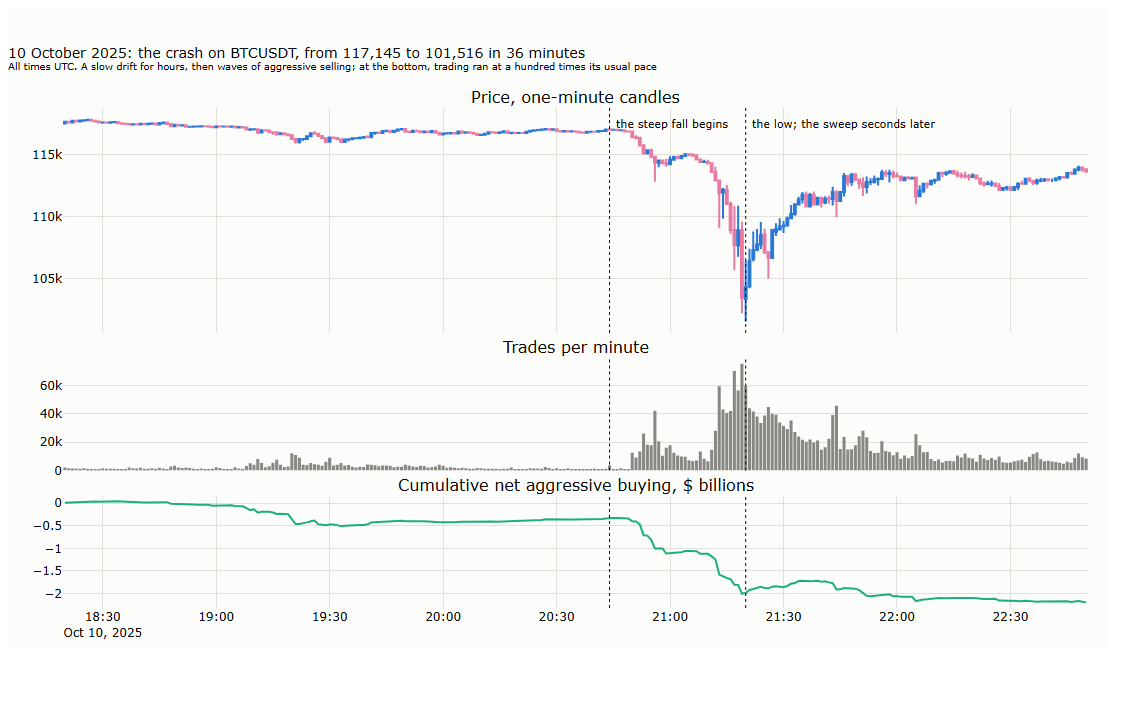

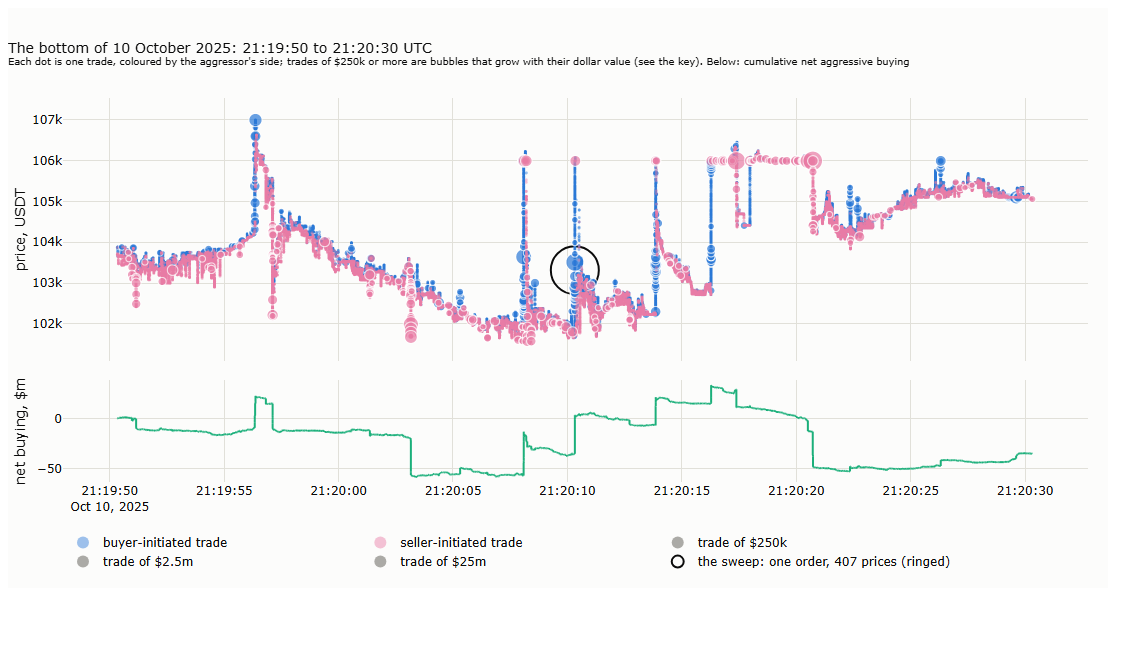

l13_extremes.py: 25 s


day,range_pct,busiest_second,busiest_trades,busiest_prices
str,f64,str,i64,i64
"""2022-09-06""",48.8,"""17:05:31""",2065,1634
"""2022-09-21""",9.9,"""18:00:40""",5072,4003
"""2021-12-04""",9.3,"""05:27:49""",1872,1538
"""2025-10-10""",7.2,"""21:19:33""",3894,2606
"""2024-12-05""",6.7,"""22:28:15""",3971,3428
"""2023-10-23""",6.3,"""18:44:39""",3520,2897
"""2022-11-08""",6.0,"""16:32:43""",2330,1544
"""2022-05-05""",5.6,"""15:08:20""",2491,1990
"""2021-10-28""",5.6,"""18:39:03""",7990,6913


**The largest sweeps**, one per day, by the number of prices swept:

day,time,side,prices,low,high,pct,usd_m,btc
str,str,str,i64,f64,f64,f64,f64,f64
"""2025-10-10""","""21:20:10.325""","""buy""",407,101881.1,104749.8,2.82,33.7,325.9
"""2024-12-05""","""03:08:23.225""","""buy""",277,103663.1,103745.3,0.08,6.0,58.0
"""2024-01-03""","""12:03:08.892""","""buy""",237,42967.5,43046.2,0.18,4.3,99.4
"""2026-08-19""","""15:28:08.070""","""buy""",220,69774.1,69916.1,0.2,1.1,15.7
"""2023-08-17""","""21:47:35.995""","""buy""",156,25898.7,25962.9,0.25,1.3,48.6
"""2023-10-23""","""22:49:26.786""","""buy""",153,33543.5,33598.2,0.16,1.9,57.2


**The second after the Fed decision**, 18:00:02 UTC on 21 September 2022:

{'trades': 1846,
 'prices': 1253,
 'low': 19879.8,
 'high': 20120.0,
 'most_prices': {'time': '18:00:02.351',
  'side': 'sell',
  'prices': 55,
  'low': 19926.6,
  'high': 19939.4,
  'pct': 0.06,
  'usd_m': 0.6,
  'btc': 29.6},
 'largest_move': {'time': '18:00:02.802',
  'side': 'sell',
  'prices': 24,
  'low': 19887.1,
  'high': 20119.0,
  'pct': 1.17,
  'usd_m': 0.1,
  'btc': 5.2}}

In [5]:
run("l13_oct10.py")
pictures("13_05_crash_evening", "13_06_crash_sweep")
run("l13_extremes.py")
ex = result("l13_extremes.json")
display(table([{k: v for k, v in r.items() if not k.startswith("sweeps")} for r in ex["extreme_days"]]))
display(Markdown("**The largest sweeps**, one per day, by the number of prices swept:"))
display(table(ex["largest_sweeps"][:6]))
display(Markdown("**The second after the Fed decision**, 18:00:02 UTC on 21 September 2022:"))
ex["fed_second"]

### 2.3 Is one second a lucky choice? (§3.5)

The price clocks at five resolutions of their price and five targets, on 62 days spread over the five years. It takes a few minutes.

In [6]:
run("l13_robust.py")
rob = pl.read_parquet(OUT / "l13_robust_price.parquet")
display(rob.filter((pl.col("clock") == "range") & (pl.col("target") == 48)))
display(Markdown("**The dollar clock: window of the adaptive threshold** (§3.4)"))
result("l13_robust_dollar.json")

l13_robust.py: 16 s


clock,resolution,target,scale_needed,dispersion,busiest_vs_median,share_bars_3_trades_or_fewer,fed_day_vs_median
str,str,i64,f64,f64,f64,f64,f64
"""range""","""1 s""",48,1.3,0.86,9.9,0.0,3.9
"""range""","""100 ms""",48,1.34,0.92,11.0,0.0,6.9
"""range""","""30 s""",48,1.08,0.68,5.9,0.0,2.2
"""range""","""5 s""",48,1.24,0.79,8.0,0.0,2.9
"""range""","""every fill""",48,1.37,1.19,109.0,0.213,109.0


**The dollar clock: window of the adaptive threshold** (§3.4)

[{'window_days': 14,
  'mean_bars_per_day': 51.3,
  'weeks_within_25pct': 0.74,
  'by_year': [{'y': 2021, 'bars': 49.8},
   {'y': 2022, 'bars': 50.5},
   {'y': 2023, 'bars': 53.9},
   {'y': 2024, 'bars': 51.8},
   {'y': 2025, 'bars': 49.7},
   {'y': 2026, 'bars': 50.4}]},
 {'window_days': 28,
  'mean_bars_per_day': 51.6,
  'weeks_within_25pct': 0.74,
  'by_year': [{'y': 2021, 'bars': 49.4},
   {'y': 2022, 'bars': 50.1},
   {'y': 2023, 'bars': 54.8},
   {'y': 2024, 'bars': 53.4},
   {'y': 2025, 'bars': 50.0},
   {'y': 2026, 'bars': 49.9}]},
 {'window_days': 56,
  'mean_bars_per_day': 51.9,
  'weeks_within_25pct': 0.65,
  'by_year': [{'y': 2021, 'bars': 48.1},
   {'y': 2022, 'bars': 49.0},
   {'y': 2023, 'bars': 56.6},
   {'y': 2024, 'bars': 55.8},
   {'y': 2025, 'bars': 48.9},
   {'y': 2026, 'bars': 49.3}]}]

### 2.4 Do the clocks differ, and are their returns closer to normal? (§4, §5)

l13_s45.py: 5 s


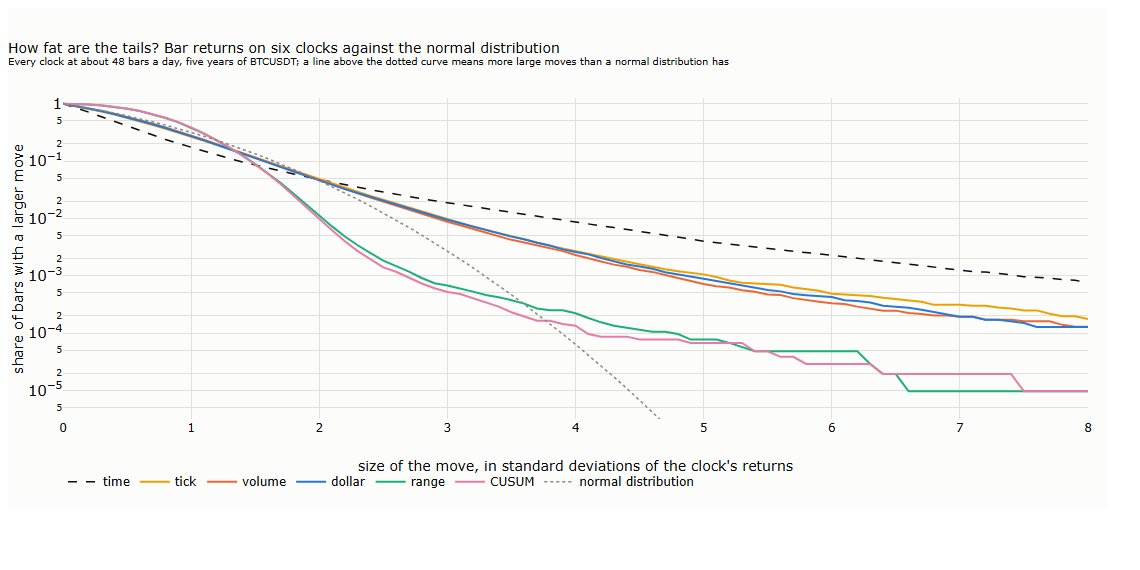

**Correlation of bars per hour** (§4)

clock,time,tick,volume,dollar,range,cusum
str,f64,f64,f64,f64,f64,f64
"""time""",NaN,NaN,NaN,NaN,NaN,NaN
"""tick""",NaN,1.0,0.93,0.92,0.89,0.88
"""volume""",NaN,0.93,1.0,0.96,0.83,0.82
"""dollar""",NaN,0.92,0.96,1.0,0.82,0.8
"""range""",NaN,0.89,0.83,0.82,1.0,1.0
"""cusum""",NaN,0.88,0.82,0.8,1.0,1.0


**Minutes per bar** (§4)

clock,p10,median,p90
str,f64,f64,f64
"""time""",30.0,30.0,30.0
"""tick""",4.6,21.1,57.3
"""volume""",3.7,20.0,62.7
"""dollar""",3.7,20.0,62.5
"""range""",0.9,10.1,64.3
"""cusum""",0.8,10.0,64.6


**Returns** (§5)

clock,bars,excess_kurtosis,skew,beyond_4sd_per_10000,ac1_returns,ac1_squared,ac1_abs
str,i64,f64,f64,f64,f64,f64,f64
"""time""",87311,23.8,-0.33,86.1,-0.013,0.219,0.309
"""tick""",96761,4.3,-0.04,26.8,-0.018,0.277,0.194
"""volume""",93593,2.6,-0.01,23.0,-0.016,0.256,0.192
"""dollar""",93872,4.4,-0.04,25.9,-0.015,0.249,0.2
"""range""",104204,-1.0,0.01,2.2,0.005,0.349,0.33
"""cusum""",104091,-1.1,0.01,1.3,0.004,0.33,0.333


In [7]:
run("l13_s45.py")
pictures("13_04_tails")
s45 = result("l13_s45.json")
display(Markdown("**Correlation of bars per hour** (§4)"))
display(table([{"clock": a, **v} for a, v in s45["hourly_count_corr"].items()]))
display(Markdown("**Minutes per bar** (§4)"))
display(table([{"clock": a, **v} for a, v in s45["minutes_per_bar"].items()]))
display(Markdown("**Returns** (§5)"))
table([{"clock": a, **v} for a, v in s45["returns"].items()])

## 3. Imbalance bars

Lecture §6. López de Prado's construction in its two readings, from many starting values; the fixed band over a grid of its settings
and of the horizon of the flow's variance; the out-of-sample test of September to November 2025; and the lecture's three figures.
The full run takes about 6 minutes; set `RUN_IMBALANCE = True` in §0 to run it.

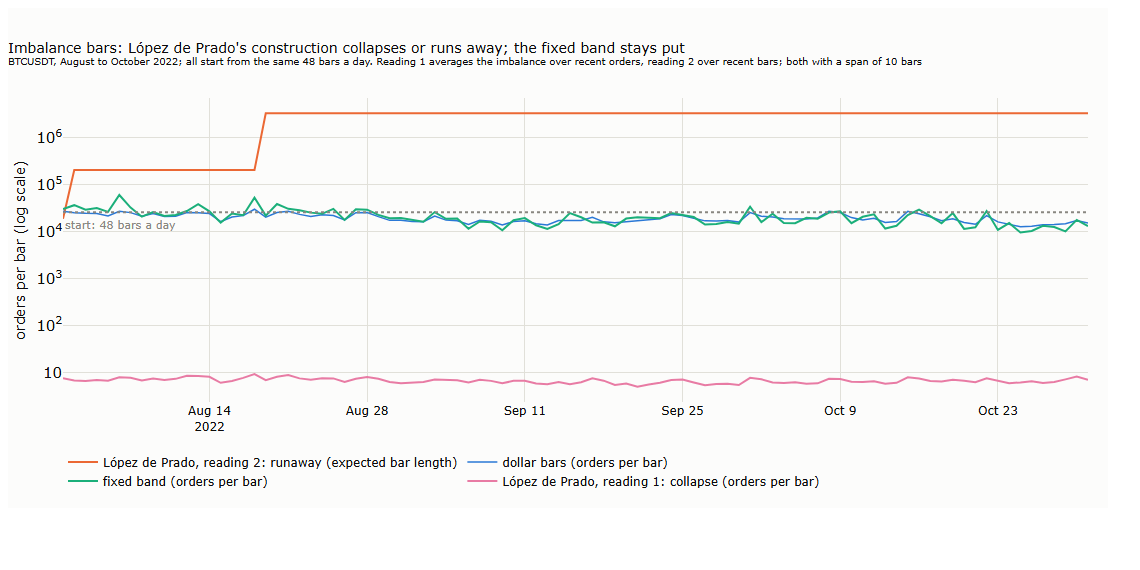

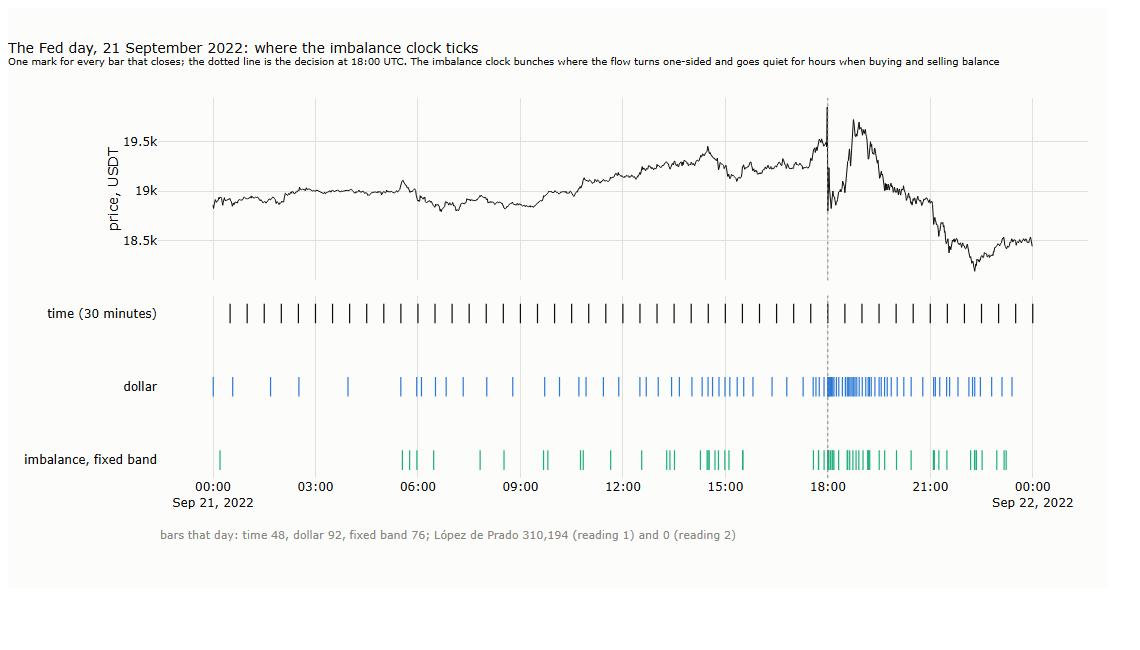

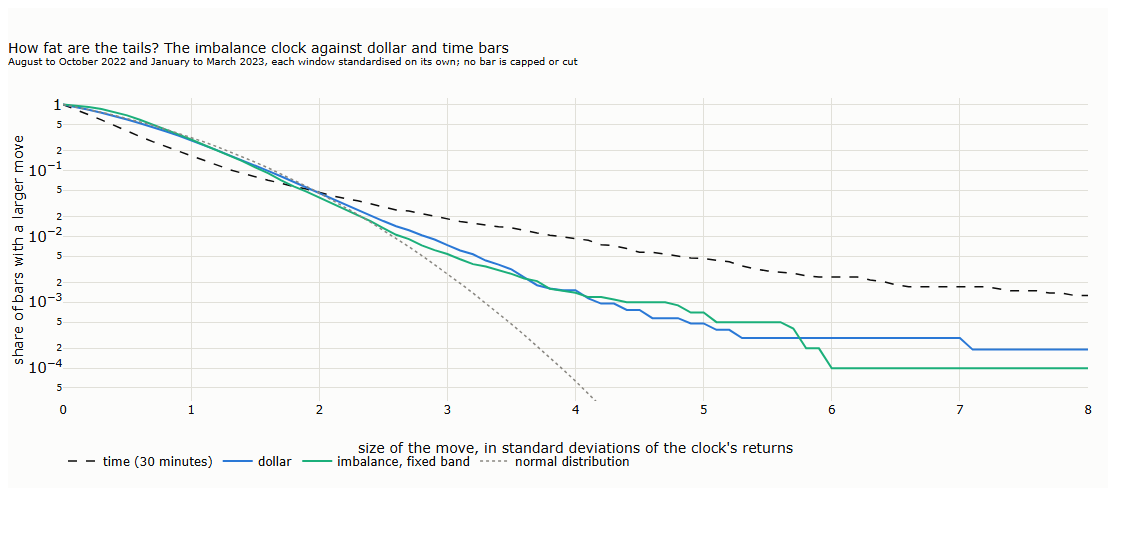

In [8]:
if RUN_IMBALANCE:
    run("l13_s6.py")                         # both constructions on two windows, the fixed band over its grid (about 4 minutes)
    run("l13_s6_ldp_init.py", show=True)     # reading 1 from sixteen starting values
    run("l13_s6_ldp_bar.py", show=True)      # reading 2 from 27 combinations of span and starting values
    run("l13_s6_stats.py")
    run("l13_s6_horizon.py")                 # the horizon of the variance: 1, 5 and 30 minutes, constants from the burn-in (about a minute)
    run("l13_s6_oos.py")                     # September to November 2025, every setting fixed
    run("l13_s6_charts.py")
pictures("13_13_imbalance_failures", "13_14_imbalance_fed_day", "13_15_imbalance_tails")

In [9]:
if (OUT / "l13_s6_oos.json").exists():
    hz = result("l13_s6_horizon_raw.json"); oos = result("l13_s6_oos.json"); ch = result("l13_s6_charts.json")
    display(Markdown(f"**Constants of the fixed band from the burn-in**, by horizon of the variance: {hz['K']}"))
    display(Markdown("**Out of sample**, September to November 2025:"))
    display(table([{"clock": k, **{a: b for a, b in v.items()}} for k, v in oos.items() if k != "K"]))
    display(Markdown("**Tails**, both windows of the comparison:"))
    display(table([{"clock": k, **v} for k, v in ch["tails"].items()]))
    ch["fed_day"]
else:
    print("no results yet: set RUN_IMBALANCE = True in §0")

**Constants of the fixed band from the burn-in**, by horizon of the variance: {'60': 0.9304340030613444, '300': 0.85262024847664, '1800': 0.8217245545659246}

**Out of sample**, September to November 2025:

clock,bpd_mean,bpd_min,bpd_max,oct10,oct11,bars,kurt,beyond4,ac1_ret,ac1_abs,usd_cv,min_p10,min_med,min_p90,min_max,flow_ret_corr
str,f64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""band""",43.8,7,156,156,46,3986,9.9,40.1,-0.068,0.328,0.97,0.42,11.8,89.7,980.0,0.38
"""dollar""",49.8,13,160,null,null,4533,4.1,28.7,0.005,0.237,0.13,4.34,21.7,61.7,230.0,0.63
"""time""",48.0,48,48,null,null,4367,18.2,52.7,-0.017,0.36,1.16,29.99,30.0,30.0,30.0,0.5


**Tails**, both windows of the comparison:

clock,bars,beyond_4sd_per_10000,excess_kurtosis
str,i64,f64,f64
"""time (30 minutes)""",8734,93.9,22.7
"""dollar""",10495,15.2,3.4
"""imbalance, fixed band""",10039,13.9,1.1


## 4. Seasonality

Lecture §7. The five hypotheses are tested on twenty calendar slots fixed in advance, each against its control, with the same measures
and a correction for the 120 tests (Benjamini and Hochberg, 1995). Then the daylight-saving test, the round-time spike at one-second
resolution, option expiries, releases by period, and when each clock makes you trade.

### 4.1 Five hypotheses, twenty slots (§7.1 to §7.4)

l13_s7h.py: 6 s


l13_s7h_charts.py: 5 s


l13_s7h_tables.py: 1 s


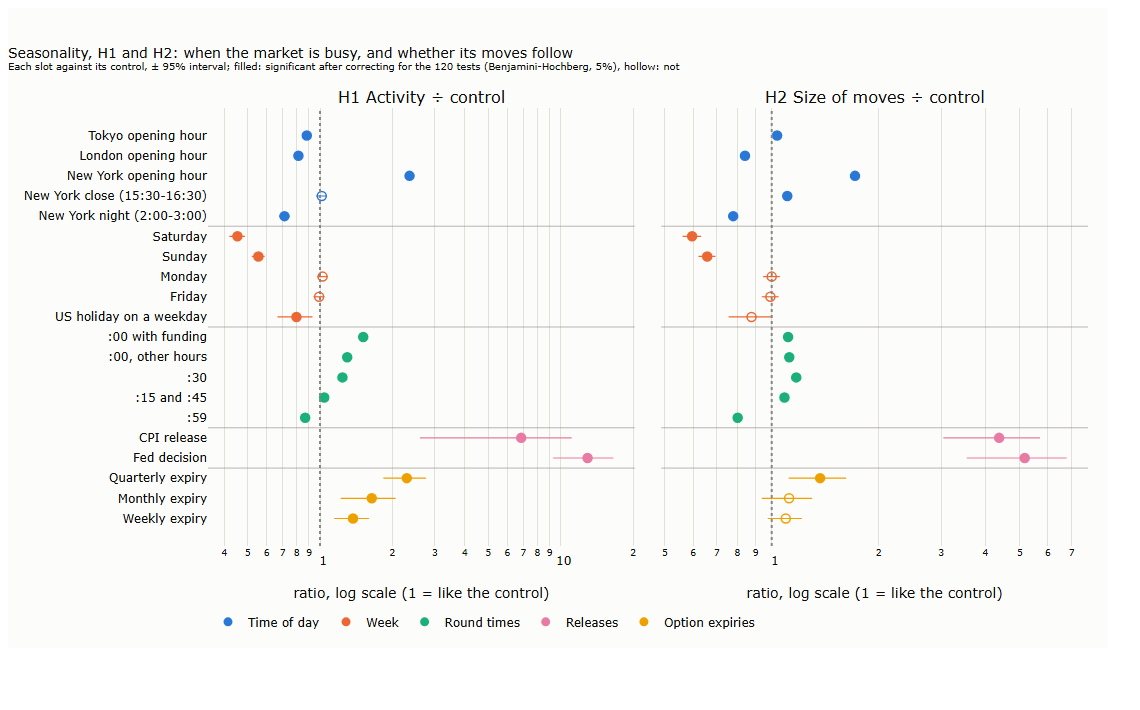

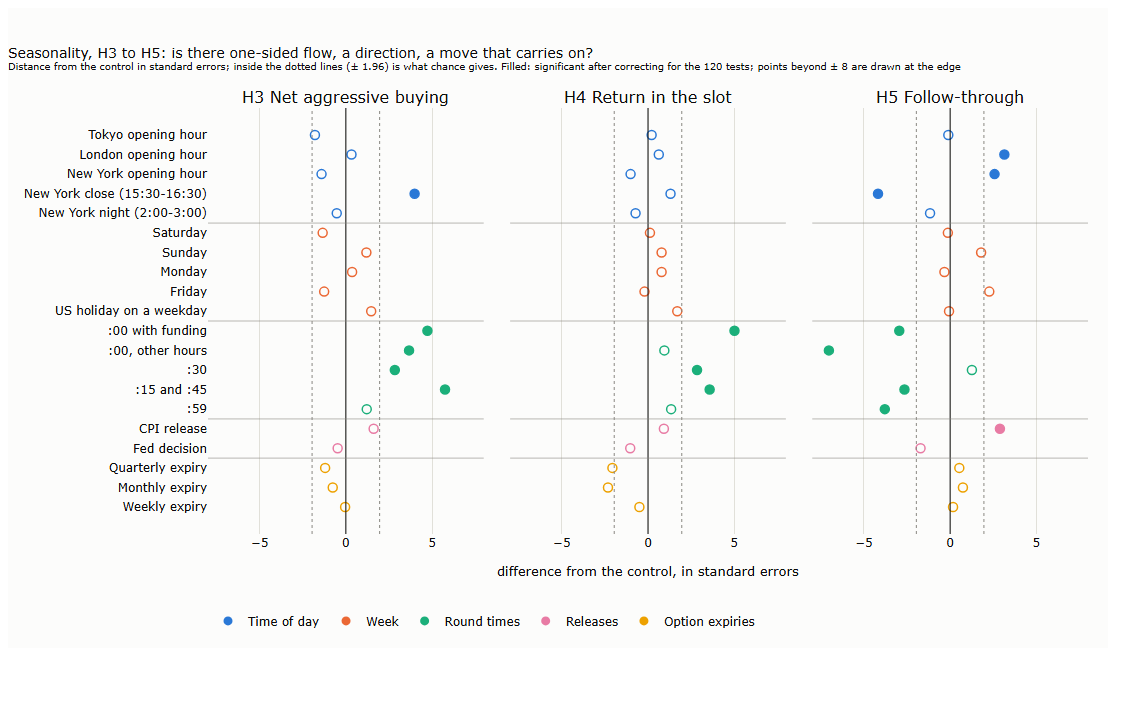

**H1 and H2: activity and the size of moves**

| Slot | n | Activity, slot ÷ control (95% interval) | q | Size of moves, slot ÷ control (95% interval) | q |
|---|---|---|---|---|---|
| Tokyo opening hour | 1,299 | 0.88 (0.85–0.92) | < 0.001 | 1.04 (1.00–1.07) | 0.041 |
| London opening hour | 1,299 | 0.81 (0.78–0.85) | < 0.001 | 0.84 (0.82–0.86) | < 0.001 |
| New York opening hour | 1,299 | 2.36 (2.26–2.45) | < 0.001 | 1.72 (1.66–1.77) | < 0.001 |
| New York close, 15:30–16:30 | 1,299 | 1.02 (0.96–1.07) | 0.746 | 1.11 (1.07–1.14) | < 0.001 |
| New York night, 2:00–3:00 | 1,299 | 0.71 (0.68–0.75) | < 0.001 | 0.78 (0.76–0.80) | < 0.001 |
| Saturday | 260 | 0.45 (0.42–0.49) | < 0.001 | 0.60 (0.56–0.63) | < 0.001 |
| Sunday | 260 | 0.55 (0.52–0.59) | < 0.001 | 0.66 (0.62–0.69) | < 0.001 |
| Monday | 227 | 1.03 (0.97–1.08) | 0.632 | 1.00 (0.95–1.05) | 0.915 |
| Friday | 253 | 0.99 (0.94–1.04) | 0.847 | 0.99 (0.94–1.05) | 0.830 |
| US holiday on a weekday | 55 | 0.80 (0.67–0.93) | 0.007 | 0.88 (0.76–1.00) | 0.108 |
| Minute :00, with funding | 3,897 | 1.51 (1.44–1.58) | < 0.001 | 1.11 (1.08–1.15) | < 0.001 |
| Minute :00, other hours | 27,279 | 1.30 (1.26–1.34) | < 0.001 | 1.12 (1.10–1.14) | < 0.001 |
| Minute :30 | 31,175 | 1.24 (1.20–1.28) | < 0.001 | 1.17 (1.16–1.19) | < 0.001 |
| Minutes :15 and :45 | 62,351 | 1.04 (1.02–1.06) | < 0.001 | 1.09 (1.07–1.10) | < 0.001 |
| Minute :59 | 31,175 | 0.87 (0.85–0.89) | < 0.001 | 0.80 (0.78–0.82) | < 0.001 |
| CPI release | 59 | 6.86 (2.60–11.11) | < 0.001 | 4.38 (3.05–5.70) | < 0.001 |
| Fed decision | 40 | 12.94 (9.31–16.58) | < 0.001 | 5.16 (3.55–6.78) | < 0.001 |
| Quarterly expiry | 20 | 2.29 (1.83–2.76) | < 0.001 | 1.37 (1.12–1.62) | 0.024 |
| Monthly expiry | 40 | 1.64 (1.22–2.06) | 0.010 | 1.12 (0.94–1.30) | 0.381 |
| Weekly expiry | 200 | 1.37 (1.15–1.60) | 0.004 | 1.10 (0.97–1.22) | 0.247 |

**H3: net aggressive buying**

| Slot | n | Net aggressive buying, % of dollars: slot (s.e.) | Control (s.e.) | q |
|---|---|---|---|---|
| Tokyo opening hour | 1,299 | −0.9 (0.2) | −0.4 (0.1) | 0.146 |
| London opening hour | 1,299 | −0.4 (0.2) | −0.4 (0.1) | 0.847 |
| New York opening hour | 1,299 | −0.7 (0.2) | −0.4 (0.1) | 0.276 |
| New York close, 15:30–16:30 | 1,299 | +0.5 (0.2) | −0.4 (0.1) | < 0.001 |
| New York night, 2:00–3:00 | 1,299 | −0.6 (0.3) | −0.4 (0.1) | 0.746 |
| Saturday | 260 | −0.7 (0.2) | −0.4 (0.1) | 0.331 |
| Sunday | 260 | −0.2 (0.2) | −0.4 (0.1) | 0.369 |
| Monday | 227 | −0.4 (0.2) | −0.4 (0.1) | 0.830 |
| Friday | 253 | −0.7 (0.2) | −0.4 (0.1) | 0.346 |
| US holiday on a weekday | 55 | +0.1 (0.3) | −0.4 (0.1) | 0.276 |
| Minute :00, with funding | 3,897 | +1.3 (0.5) | −1.0 (0.1) | < 0.001 |
| Minute :00, other hours | 27,279 | −0.2 (0.2) | −1.0 (0.1) | < 0.001 |
| Minute :30 | 31,175 | −0.4 (0.2) | −1.0 (0.1) | 0.012 |
| Minutes :15 and :45 | 62,351 | −0.0 (0.1) | −1.0 (0.1) | < 0.001 |
| Minute :59 | 31,175 | −0.8 (0.2) | −1.0 (0.1) | 0.378 |
| CPI release | 59 | +3.3 (1.5) | −1.6 (2.6) | 0.214 |
| Fed decision | 40 | −1.0 (1.8) | +0.7 (3.2) | 0.774 |
| Quarterly expiry | 20 | −4.3 (2.3) | −1.5 (0.8) | 0.381 |
| Monthly expiry | 40 | −3.0 (1.9) | −1.5 (0.8) | 0.632 |
| Weekly expiry | 200 | −1.5 (0.8) | −1.5 (0.8) | 0.969 |

**H4: return in the window and before it**

| Slot | n | Return in the window, bp: slot (s.e.) | Control (s.e.) | q | Return in the window before, bp: slot (s.e.) | Control (s.e.) | q |
|---|---|---|---|---|---|---|---|
| Tokyo opening hour | 1,299 | +0.4 (1.7) | +0.1 (0.3) | 0.915 | −2.4 (1.4) | +0.0 (0.3) | 0.189 |
| London opening hour | 1,299 | +0.9 (1.4) | +0.1 (0.3) | 0.704 | −0.7 (1.3) | +0.0 (0.3) | 0.757 |
| New York opening hour | 1,299 | −2.6 (2.6) | +0.1 (0.3) | 0.467 | +0.1 (2.1) | +0.0 (0.3) | 0.969 |
| New York close, 15:30–16:30 | 1,299 | +2.3 (1.7) | +0.1 (0.3) | 0.331 | +0.4 (1.9) | +0.0 (0.3) | 0.915 |
| New York night, 2:00–3:00 | 1,299 | −0.9 (1.3) | +0.1 (0.3) | 0.632 | +1.6 (1.3) | +0.0 (0.3) | 0.355 |
| Saturday | 260 | +0 (9) | −1 (8) | 0.956 | −6 (19) | +2 (8) | 0.828 |
| Sunday | 260 | +11 (13) | −1 (8) | 0.610 | +0 (9) | +2 (8) | 0.947 |
| Monday | 227 | +17 (22) | −1 (8) | 0.610 | +11 (14) | +2 (8) | 0.741 |
| Friday | 253 | −6 (19) | −1 (8) | 0.915 | −43 (17) | +2 (8) | 0.051 |
| US holiday on a weekday | 55 | +59 (34) | −1 (8) | 0.189 | +66 (37) | +2 (8) | 0.189 |
| Minute :00, with funding | 3,897 | +0.59 (0.13) | −0.07 (0.02) | < 0.001 | −1.3 (0.7) | +0.0 (0.1) | 0.098 |
| Minute :00, other hours | 27,279 | −0.01 (0.06) | −0.07 (0.02) | 0.494 | +0.0 (0.3) | +0.0 (0.1) | 0.969 |
| Minute :30 | 31,175 | +0.11 (0.06) | −0.07 (0.02) | 0.017 | +0.2 (0.2) | +0.0 (0.1) | 0.686 |
| Minutes :15 and :45 | 62,351 | +0.09 (0.04) | −0.07 (0.02) | < 0.001 | +0.0 (0.2) | +0.0 (0.1) | 0.989 |
| Minute :59 | 31,175 | −0.01 (0.04) | −0.07 (0.02) | 0.277 | −0.1 (0.2) | +0.0 (0.1) | 0.746 |
| CPI release | 59 | +13 (17) | −3 (4) | 0.527 | +11 (4) | +3 (4) | 0.342 |
| Fed decision | 40 | −16 (17) | +1 (2) | 0.467 | +25 (10) | −5 (6) | 0.027 |
| Quarterly expiry | 20 | −20 (8) | −2 (2) | 0.122 | −8 (10) | +4 (2) | 0.362 |
| Monthly expiry | 40 | −15 (5) | −2 (2) | 0.059 | −9 (5) | +4 (2) | 0.049 |
| Weekly expiry | 200 | −4 (2) | −2 (2) | 0.757 | +3 (2) | +4 (2) | 0.830 |

**H5: follow-through**

| Slot | n | Correlation, return in the window with return in the next window: slot | Control | Share of occurrences in the same direction: slot | Control | q (slot ≠ control) |
|---|---|---|---|---|---|---|
| Tokyo opening hour | 1,299 | −0.01 | −0.01 | 46% | 47% | 0.956 |
| London opening hour | 1,299 | +0.08 | −0.01 | 46% | 47% | 0.005 |
| New York opening hour | 1,299 | +0.07 | −0.01 | 50% | 47% | 0.025 |
| New York close, 15:30–16:30 | 1,299 | −0.12 | −0.01 | 43% | 47% | < 0.001 |
| New York night, 2:00–3:00 | 1,299 | −0.04 | −0.01 | 48% | 47% | 0.381 |
| Saturday | 260 | −0.05 | −0.04 | 51% | 47% | 0.951 |
| Sunday | 260 | +0.08 | −0.04 | 48% | 47% | 0.149 |
| Monday | 227 | −0.07 | −0.04 | 44% | 47% | 0.847 |
| Friday | 253 | +0.12 | −0.04 | 51% | 47% | 0.053 |
| US holiday on a weekday | 55 | −0.05 | −0.04 | 55% | 47% | 0.969 |
| Minute :00, with funding | 3,897 | −0.04 | +0.01 | 50% | 50% | 0.009 |
| Minute :00, other hours | 27,279 | −0.04 | +0.01 | 50% | 50% | < 0.001 |
| Minute :30 | 31,175 | +0.01 | +0.01 | 50% | 50% | 0.346 |
| Minutes :15 and :45 | 62,351 | −0.01 | +0.01 | 49% | 50% | 0.021 |
| Minute :59 | 31,175 | −0.02 | +0.01 | 49% | 50% | < 0.001 |
| CPI release | 59 | +0.45 | −0.07 | 42% | 52% | 0.011 |
| Fed decision | 40 | −0.32 | +0.06 | 42% | 57% | 0.175 |
| Quarterly expiry | 20 | +0.11 | −0.02 | 55% | 44% | 0.746 |
| Monthly expiry | 40 | +0.11 | −0.02 | 30% | 44% | 0.632 |
| Weekly expiry | 200 | −0.00 | −0.02 | 50% | 44% | 0.936 |

In [10]:
run("l13_s7h.py"); run("l13_s7h_charts.py"); run("l13_s7h_tables.py")
pictures("13_08_h1_h2_activity_volatility", "13_09_h3_h5_flow_direction_follow")
T = result("l13_s7h_tables.json")
for title, k in (("H1 and H2: activity and the size of moves", "all12"), ("H3: net aggressive buying", "all3"),
                 ("H4: return in the window and before it", "all4"), ("H5: follow-through", "all5")):
    display(Markdown(f"**{title}**\n\n" + T[k]))

### 4.2 Whose day is it? The daylight-saving test, and when each clock trades (§7.2, §7.8)

l13_s7.py: 5 s


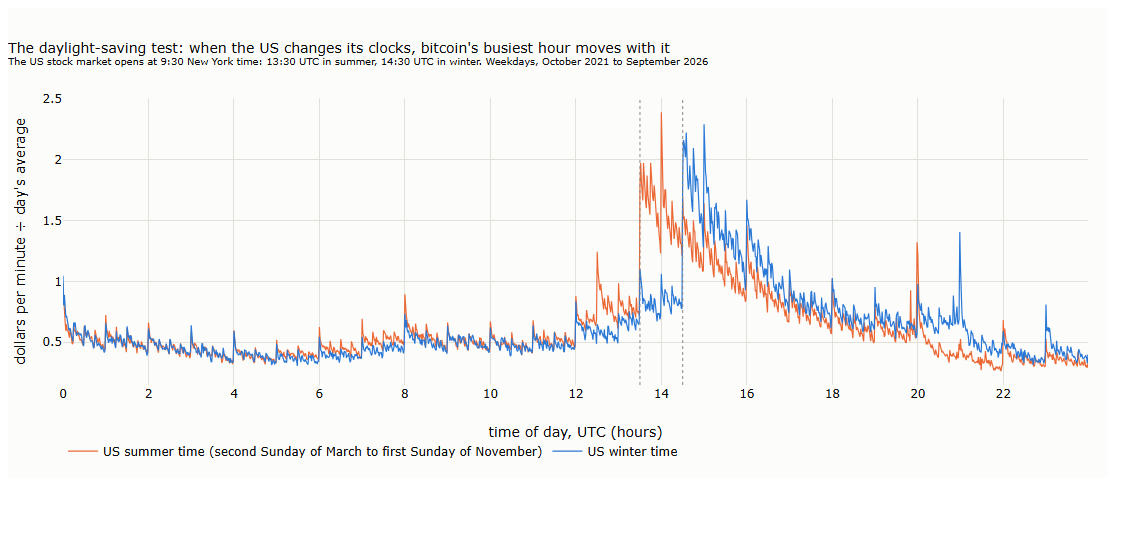

clock,deep_hours,thin_hours,round_minute,in_bursts
str,f64,f64,f64,f64
"""time""",0.25,0.25,1.0,0.0009
"""tick""",0.409,0.146,0.079,0.0254
"""volume""",0.422,0.137,0.079,0.0327
"""dollar""",0.423,0.136,0.079,0.0337
"""range""",0.439,0.125,0.075,0.0551
"""cusum""",0.439,0.125,0.075,0.0603


{'busiest_hour_summer': 14,
 'busiest_hour_share_summer': 0.088,
 'peak_minute_summer': '14:00',
 'open_minute_jump_summer': 2.48,
 'busiest_hour_winter': 15,
 'busiest_hour_share_winter': 0.088,
 'peak_minute_winter': '15:00',
 'open_minute_jump_winter': 2.43,
 'dollars_by_weekday_vs_mean': {'1': 1.19,
  '2': 1.17,
  '3': 1.18,
  '4': 1.13,
  '5': 1.15,
  '6': 0.53,
  '7': 0.66},
 'us_holiday_vs_weekday': 0.71,
 'us_holidays_on_weekdays': 55,
 'round_minutes': {'0': {'activity_vs_hour': 1.11,
   'trade_size_vs_other': 1.1,
   'one_sidedness_vs_other': 0.91},
  '1': {'activity_vs_hour': 0.92,
   'trade_size_vs_other': 1.05,
   'one_sidedness_vs_other': 1.02},
  '15': {'activity_vs_hour': 0.84,
   'trade_size_vs_other': 1.02,
   'one_sidedness_vs_other': 1.0},
  '30': {'activity_vs_hour': 0.86,
   'trade_size_vs_other': 1.02,
   'one_sidedness_vs_other': 0.98},
  '45': {'activity_vs_hour': 0.78,
   'trade_size_vs_other': 1.01,
   'one_sidedness_vs_other': 1.0},
  '59': {'activity_vs_hou

In [11]:
run("l13_s7.py")
pictures("13_07_time_of_day_dst")
s7 = result("l13_s7.json")
display(table(s7["when_clocks_trade"]))
{k: v for k, v in s7.items() if k != "when_clocks_trade"}

### 4.3 Round times at one-second resolution (§7.2)

l13_round_seconds.py: 5 s


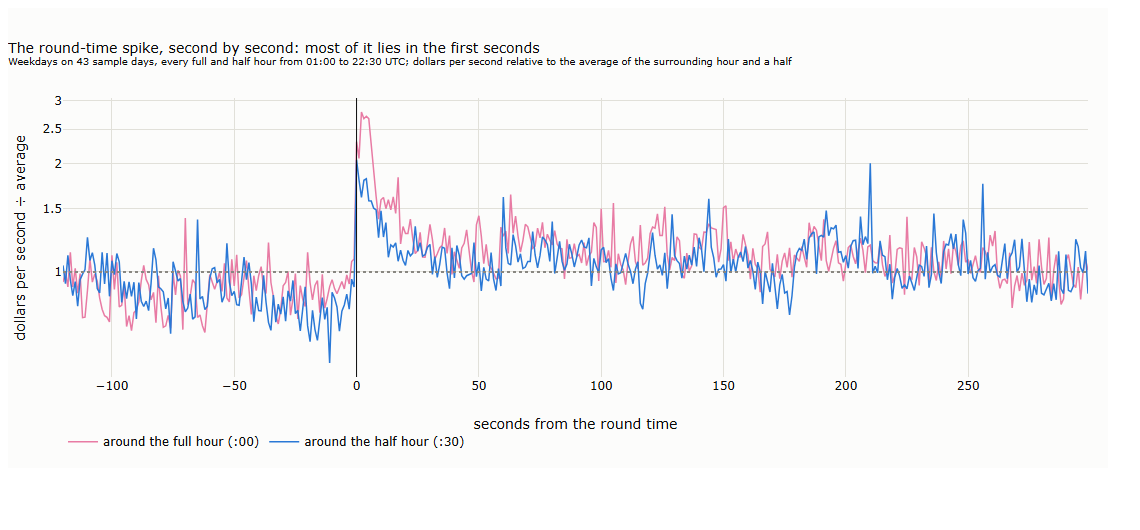

{':00': {'first_second': 2.3,
  'first_5s': 2.51,
  'first_10s': 2.24,
  'seconds_10_60': 1.24,
  'minutes_1_5': 1.12,
  'minute_before': 0.92,
  'last_5s_before': 0.99,
  'seconds_above_2x': 7,
  'back_below_1_5x_after_s': 9},
 ':30': {'first_second': 2.1,
  'first_5s': 1.82,
  'first_10s': 1.65,
  'seconds_10_60': 1.09,
  'minutes_1_5': 1.08,
  'minute_before': 0.84,
  'last_5s_before': 0.87,
  'seconds_above_2x': 2,
  'back_below_1_5x_after_s': 8},
 'windows': {':00': 946, ':30': 946},
 'days': 43}

In [12]:
run("l13_round_seconds.py")
pictures("13_10_round_seconds")
result("l13_round_seconds.json")

### 4.4 Releases by period, the drift before Fed decisions, option expiries (§7.3 to §7.5)

l13_releases.py: 2 s


l13_expiry.py: 4 s


l13_settlement.py: 2 s


**CPI and Fed decisions by period** (§7.4)

event,period,n,first_move_median_abs_bp,follow_corr,p
str,str,i64,i64,f64,f64
"""CPI""","""2021–2022""",15,187,0.51,0.05
"""CPI""","""2023""",12,29,0.62,0.03
"""CPI""","""2024–2026""",32,43,0.13,0.49
"""Fed decision""","""2021–2022""",10,130,-0.51,0.14
"""Fed decision""","""2023""",8,28,0.06,0.89
"""Fed decision""","""2024–2026""",22,40,-0.05,0.84


**The drift before Fed decisions** (§7.3)

period,n,before_30m_bp,se_30m,week_earlier_30m,share_up,before_24h_bp,se_24h,week_earlier_24h
str,i64,i64,i64,i64,f64,i64,i64,i64
"""2021–2022""",10,59,34,-6,0.6,139,95,50
"""2023""",8,11,8,2,0.5,59,29,56
"""2024–2026""",22,15,6,-7,0.73,-17,46,31
"""All""",40,25,10,-5,0.65,37,37,41


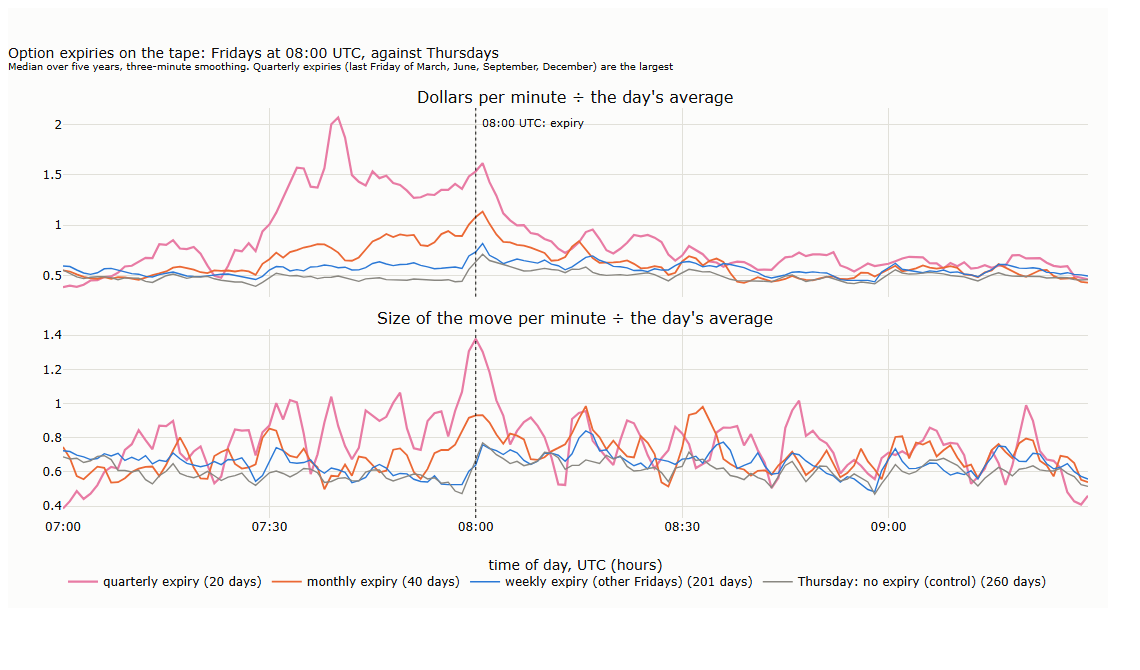

**Back to the settlement average?** (§7.5)

days,n,corr,p,moved_back,p_back
str,i64,f64,f64,f64,f64
"""monthly and quarterly expiries, 30 min""",60,-0.19,0.14,0.6,0.16
"""Thursdays, 30 min""",260,-0.05,0.42,0.55,0.09
"""monthly and quarterly expiries, 60 min""",60,-0.16,0.24,0.65,0.03
"""Thursdays, 60 min""",260,-0.02,0.72,0.58,0.01


In [13]:
run("l13_releases.py"); run("l13_expiry.py"); run("l13_settlement.py")
rel = result("l13_releases.json")
display(Markdown("**CPI and Fed decisions by period** (§7.4)")); display(table(rel["by_period"]))
display(Markdown("**The drift before Fed decisions** (§7.3)")); display(table(rel["fed_drift"]))
pictures("13_11_option_expiry")
display(Markdown("**Back to the settlement average?** (§7.5)"))
table([{"days": k, **v} for k, v in result("l13_settlement.json").items()])

## 5. A calendar test of your own

The method of §7.1 works for any calendar effect, in any market. Before running anything:

1. **State the hypothesis and its reason.** What should happen in the slot, and why? What would reject it?
2. **Fix the slot and its control from a schedule or a definition,** not from the data. The control should differ from the slot only in the
   feature being tested.
3. **Then measure,** with the same measures as the lecture, and **correct for the number of tests**: yours, added to the lecture's 120.

The cell below imports the functions of `l13_s7h.py` (building the minute grid takes about a minute) and tests one example: the first hour
of each month, 00:00 to 01:00 UTC on the first day, against the full hours of weekdays. Change the slot, the control and the windows
to test your own.

In [14]:
import l13_s7h as S                 # the minute grid and the measures of §7.1

# the slot: minute indices at which each occurrence starts; S.DAYS lists the days, S.nd their number, S.local_starts(...) gives local times
slot = [i * 1440 for i in range(S.nd) if S.DAYS[i].day == 1]
control = S.hour_ctl                # every full hour of a weekday
L, B, A = 60, 60, 60                # window, the window before it, the window after it, in minutes

r = S.summ(S.inst(slot, L, B, A), S.inst(control, L, B, A))
table([{"measure": k, "value": round(v, 4) if isinstance(v, float) else v} for k, v in r.items()])

measure,value
str,f64
"""n""",59.0
"""n_ctl""",31174.0
"""act""",0.91
"""act_se""",0.12
"""act_ctl""",1.18
"""act_ctl_se""",0.01
"""act_p""",0.0276
"""vol""",1.04
"""vol_se""",0.06


**Reading the result.** `act` and `vol` are activity and the size of moves, `flow` net aggressive buying in % of dollars, `ret` and `before`
the return in the window and before it in basis points, each with its control (`_ctl`), standard error (`_se`) and p-value (`_p`);
`follow` is the follow-through. Before calling an effect real, adjust its p-values for all the tests you ran, as in §7.1, and ask
whether its size would survive the costs of trading on it (Lecture 15).